# CXI Diffraction Pattern Viewer
Visualize raw diffraction patterns from `.cxi` (HDF5) files and export a scan range as a multi-page TIFF.

**Dependencies:** `h5py`, `numpy`, `matplotlib`, `tifffile`, `matplotlib_scalebar`

Install if needed:
```bash
pip install h5py numpy matplotlib tifffile matplotlib-scalebar
```

In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import tifffile
import os
from pathlib import Path

# Optional: prettier scale bars via matplotlib-scalebar
try:
    from matplotlib_scalebar.scalebar import ScaleBar
    HAS_SCALEBAR = True
except ImportError:
    HAS_SCALEBAR = False
    print("matplotlib-scalebar not found; falling back to manual scale bar.")

print("Imports OK")

matplotlib-scalebar not found; falling back to manual scale bar.
Imports OK


## 1. Configuration
Set your CXI file path, HDF5 dataset path, pixel size, and scan range here.

In [2]:
# ── USER SETTINGS ────────────────────────────────────────────────────────────

CXI_FILE = "NS_260310017_ccdframes_0_0.cxi"           # Path to your .cxi file

# HDF5 dataset path inside the CXI file that holds the 2D diffraction stack.
# Common paths — uncomment the one that matches your data:
FOLDER_PATH = '/cosmic-dtn/groups/cosmic/Data/2026/03/260310/'


FILE_PATH = FOLDER_PATH + CXI_FILE
# Scan index range (Python slice, inclusive start, exclusive stop)
SCAN_START = 0     # First scan index to export
SCAN_STOP  = 10    # Last scan index (exclusive); set to None for all frames

# Single-frame preview index (must be within [SCAN_START, SCAN_STOP))
PREVIEW_INDEX = 0

# Detector pixel size in metres (used for scale bar).  Examples:
#   75e-6   → 75 µm  (CSPAD, Jungfrau 1M)
#  110e-6   → 110 µm (AGIPD, LPD)
#  172e-6   → 172 µm (Pilatus)
PIXEL_SIZE_M = 75e-6

# Scale-bar length in metres shown on the preview plot
SCALEBAR_LENGTH_M = 0.5e-3   # 0.5 mm

# Colormap and display stretch for the preview plot
COLORMAP   = "viridis"    # e.g. 'inferno', 'gray', 'RdBu_r'
VMIN_PCTILE = 1           # Percentile for lower display bound (clips noise)
VMAX_PCTILE = 99.5        # Percentile for upper display bound (clips hot pixels)

# Output TIFF filename
OUTPUT_TIFF = f"diffraction_scans_{SCAN_START}-{SCAN_STOP}.tiff"

# ─────────────────────────────────────────────────────────────────────────────
print(f"Config OK — file: {CXI_FILE}  |  dataset: {FILE_PATH} ")
print(f"Scan range: [{SCAN_START} : {SCAN_STOP}]  |  preview index: {PREVIEW_INDEX}")

Config OK — file: NS_260310017_ccdframes_0_0.cxi  |  dataset: /cosmic-dtn/groups/cosmic/Data/2026/03/260310/NS_260310017_ccdframes_0_0.cxi 
Scan range: [0 : 10]  |  preview index: 0


## 2. Inspect the CXI File
Print the HDF5 tree so you can confirm the correct dataset path.

In [3]:
def print_hdf5_tree(filename, max_depth=4):
    """Recursively print all groups and datasets in an HDF5 file."""
    def _visitor(name, obj):
        depth = name.count('/')
        if depth > max_depth:
            return
        indent = '  ' * depth
        if isinstance(obj, h5py.Dataset):
            print(f"{indent}[Dataset] /{name}  shape={obj.shape}  dtype={obj.dtype}")
        elif isinstance(obj, h5py.Group):
            print(f"{indent}[Group]   /{name}")

    with h5py.File(filename, 'r') as f:
        print(f"Root attributes: {list(f.attrs.keys())}\n")
        f.visititems(_visitor)

print_hdf5_tree(FILE_PATH)

Root attributes: []

[Dataset] /cxi_version  shape=()  dtype=int64
[Group]   /entry_1
  [Group]   /entry_1/data_1
  [Group]   /entry_1/instrument_1
    [Group]   /entry_1/instrument_1/detector_1
      [Dataset] /entry_1/instrument_1/detector_1/basis_vectors  shape=(2, 3)  dtype=float64
      [Dataset] /entry_1/instrument_1/detector_1/data  shape=(2500, 512, 512)  dtype=float32
      [Dataset] /entry_1/instrument_1/detector_1/data_illumination  shape=(512, 512)  dtype=complex128
      [Dataset] /entry_1/instrument_1/detector_1/distance  shape=()  dtype=float64
      [Dataset] /entry_1/instrument_1/detector_1/mask  shape=(512, 512)  dtype=uint32
      [Dataset] /entry_1/instrument_1/detector_1/probe  shape=(512, 512)  dtype=complex128
      [Dataset] /entry_1/instrument_1/detector_1/probe_mask  shape=(512, 512)  dtype=bool
      [Dataset] /entry_1/instrument_1/detector_1/x_pixel_size  shape=()  dtype=float64
      [Dataset] /entry_1/instrument_1/detector_1/y_pixel_size  shape=()  dtype=f

In [4]:
# HDF5 internal dataset key — run print_hdf5_tree(FILE_PATH) to find yours
DATASET_PATH = "/entry_1/instrument_1/detector_1/data"  

with h5py.File(FILE_PATH, 'r') as f:
    ds = f[DATASET_PATH]          # DATASET_PATH is the internal HDF5 key
    print(ds)
    if ds.ndim == 2:
        total_scan = ds[()].astype(np.float32)
    elif ds.ndim == 3:
        total_scan = ds[()].astype(np.float32)
print(total_scan.shape)

<HDF5 dataset "data": shape (2500, 512, 512), type "<f4">
(2500, 512, 512)


In [15]:
## Define path to the energy scans 
ENERGY_PATH = "/entry_1/instrument_1/source_1/energy" 

with h5py.File(FILE_PATH, 'r') as f:
    ds = f[ENERGY_PATH]          # DATASET_PATH is the internal HDF5 key
    print(ds)
    energy = ds[()].astype(np.float32)
print(energy)

<HDF5 dataset "energy": shape (), type "<f8">
1.2096459e-16


## 3. Helper Functions

In [5]:
def load_frame(file_path, index):
    """Load a single 2D diffraction frame from a CXI file."""
    with h5py.File(file_path, 'r') as f:
        ds = f[DATASET_PATH]          # DATASET_PATH is the internal HDF5 key
        if ds.ndim == 2:
            frame = ds[()].astype(np.float32)
        elif ds.ndim == 3:
            frame = ds[index].astype(np.float32)
        else:
            raise ValueError(f"Unexpected dataset dimensions: {ds.ndim}D  shape={ds.shape}")
    return frame


def load_frame_range(file_path, start, stop):
    """Load a slice of frames; stop=None loads everything."""
    with h5py.File(file_path, 'r') as f:
        ds = f[DATASET_PATH]          # DATASET_PATH is the internal HDF5 key
        if ds.ndim == 2:
            return ds[()][np.newaxis].astype(np.float32)
        slc = slice(start, stop)
        frames = ds[slc].astype(np.float32)
    print(f"Loaded {frames.shape[0]} frames  shape/frame={frames.shape[1:]}")
    return frames


def display_stretch(frame, vmin_pctile=1, vmax_pctile=99.5):
    """Return (vmin, vmax) clipped to percentiles for display."""
    vmin = float(np.percentile(frame, vmin_pctile))
    vmax = float(np.percentile(frame, vmax_pctile))
    return vmin, vmax


def add_scale_bar_manual(ax, frame_shape, pixel_size_m, bar_length_m,
                          color='white', fontsize=10, padding_frac=0.03):
    """
    Draw a manual scale bar in the lower-left corner of the axes.
    Works even without matplotlib-scalebar.
    """
    h, w = frame_shape
    bar_px = bar_length_m / pixel_size_m
    pad_x  = w * padding_frac
    pad_y  = h * padding_frac
    x0 = pad_x
    y0 = h - pad_y
    # Horizontal bar
    ax.plot([x0, x0 + bar_px], [y0, y0], color=color, linewidth=2.5, solid_capstyle='butt')
    # End ticks
    tick_h = h * 0.012
    for xp in [x0, x0 + bar_px]:
        ax.plot([xp, xp], [y0 - tick_h, y0 + tick_h], color=color, linewidth=1.5)
    # Label
    if bar_length_m >= 1e-3:
        label = f"{bar_length_m*1e3:.4g} mm"
    else:
        label = f"{bar_length_m*1e6:.4g} µm"
    ax.text(x0 + bar_px / 2, y0 - tick_h * 2, label,
            ha='center', va='bottom', color=color, fontsize=fontsize,
            fontweight='bold')


## 4. Preview — Single Frame with Scale Bar

Frame shape: (512, 512)  |  min=0.0  max=3427.7


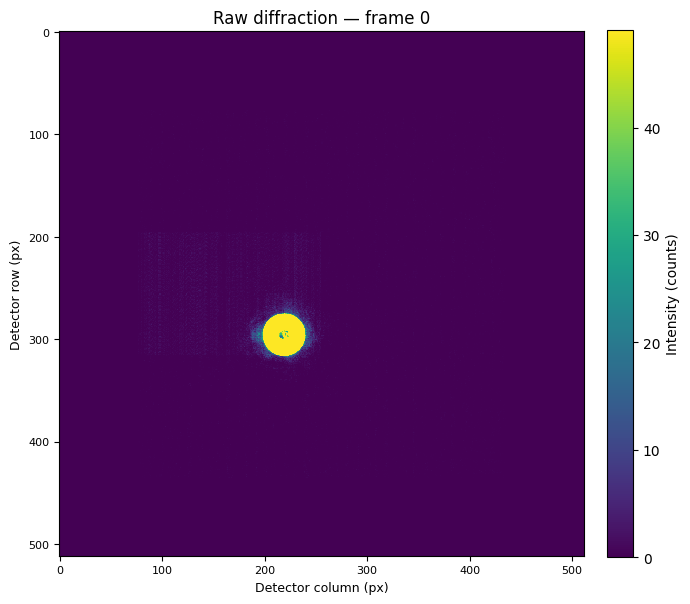

In [6]:
frame  = load_frame(FILE_PATH, PREVIEW_INDEX)
print(f"Frame shape: {frame.shape}  |  min={frame.min():.1f}  max={frame.max():.1f}")

vmin, vmax = display_stretch(frame, VMIN_PCTILE, VMAX_PCTILE)

fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(frame, cmap=COLORMAP, vmin=vmin, vmax=vmax, origin='upper',
               interpolation='nearest')

# # ── Scale bar ────────────────────────────────────────────────────────────────
# if HAS_SCALEBAR:
#     sb = ScaleBar(PIXEL_SIZE_M, 'm', length_fraction=None,
#                   fixed_value=SCALEBAR_LENGTH_M,
#                   fixed_units='m',
#                   color='white', box_alpha=0,
#                   font_properties={'size': 10, 'weight': 'bold'},
#                   location='lower left')
#     ax.add_artist(sb)
# else:
#     add_scale_bar_manual(ax, frame.shape, PIXEL_SIZE_M, SCALEBAR_LENGTH_M)

# ── Decorations ───────────────────────────────────────────────────────────────
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Intensity (counts)', fontsize=10)

ax.set_title(f"Raw diffraction — frame {PREVIEW_INDEX}", fontsize=12)
ax.set_xlabel("Detector column (px)", fontsize=9)
ax.set_ylabel("Detector row (px)", fontsize=9)
ax.tick_params(labelsize=8)

plt.tight_layout()
# plt.savefig(f"preview_frame_{PREVIEW_INDEX}.png", dpi=150, bbox_inches='tight')
plt.show()
# print(f"Preview saved → preview_frame_{PREVIEW_INDEX}.png")

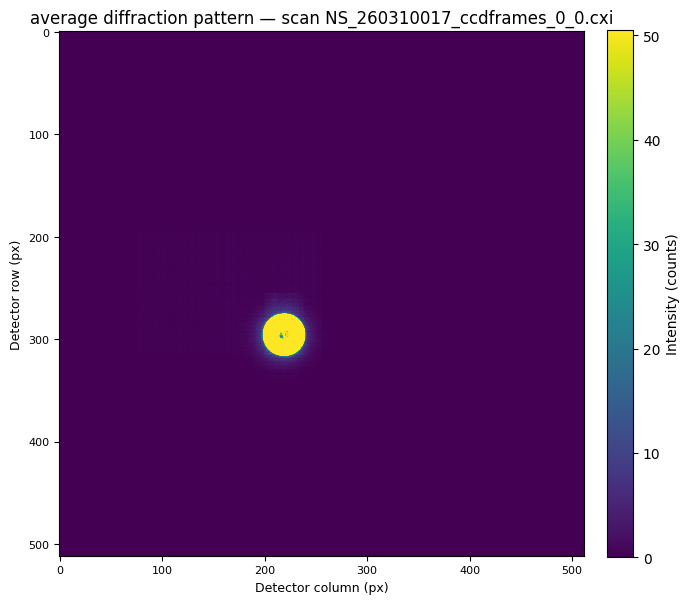

In [7]:
## average over all scan positions 
hold_diffraction_pattern = []

for i in np.arange(0, total_scan.shape[0]):
    frame  = load_frame(FILE_PATH, i)
    
    hold_diffraction_pattern.append(frame) 

hold_diffraction_pattern = np.array(hold_diffraction_pattern)
avg_diffraction_pattern =  np.mean(hold_diffraction_pattern, axis=0)
  
vmin, vmax = display_stretch(avg_diffraction_pattern, VMIN_PCTILE, VMAX_PCTILE)
    
fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(avg_diffraction_pattern, cmap=COLORMAP, vmin=vmin, vmax=vmax, origin='upper',
               interpolation='nearest')

# ── Decorations ───────────────────────────────────────────────────────────────
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Intensity (counts)', fontsize=10)

ax.set_title(f"average diffraction pattern — scan {CXI_FILE}", fontsize=12)
ax.set_xlabel("Detector column (px)", fontsize=9)
ax.set_ylabel("Detector row (px)", fontsize=9)
ax.tick_params(labelsize=8)

plt.tight_layout()
# plt.savefig(f"preview_frame_{PREVIEW_INDEX}.png", dpi=150, bbox_inches='tight')
plt.show()
# print(f"Preview saved → preview_frame_{PREVIEW_INDEX}.png")




## 5. (Optional) Quick Contact Sheet — All Frames in Range
A tiled overview so you can visually scan all patterns before deciding which are interesting.

Loaded 10 frames  shape/frame=(512, 512)


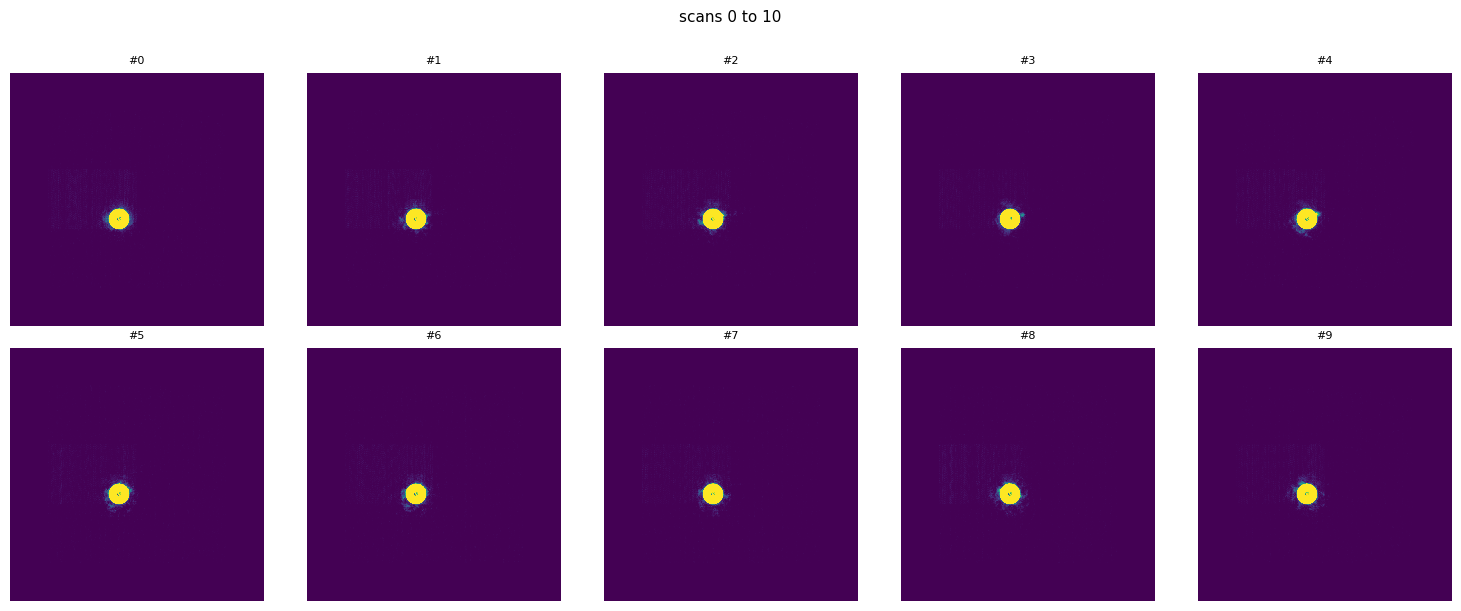

In [8]:
frames = load_frame_range(FILE_PATH, SCAN_START, SCAN_STOP)
n = len(frames)

ncols = min(n, 5)
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
axes = np.atleast_2d(axes)   # ensure 2-D array even for single-row layouts

for i, ax in enumerate(axes.flat):
    if i < n:
        fr = frames[i]
        vmin_i, vmax_i = display_stretch(fr, VMIN_PCTILE, VMAX_PCTILE)
        ax.imshow(fr, cmap=COLORMAP, vmin=vmin_i, vmax=vmax_i,
                  origin='upper', interpolation='nearest')
        ax.set_title(f"#{SCAN_START + i}", color='k', fontsize=8)
    ax.axis('off')

plt.suptitle(f"scans {SCAN_START} to {SCAN_STOP}",
             color='k', fontsize=11, y=1.01)
plt.tight_layout()
# contact_out = f"contact_sheet_{SCAN_START}-{SCAN_STOP}.png"
# plt.savefig(contact_out, dpi=120, bbox_inches='tight', facecolor='k')
plt.show()
# print(f"Contact sheet saved → {contact_out}")

## 6. Export All Frames in Range as a Multi-Page TIFF

Saves:
- **Raw float32 stack** — lossless, full precision, one frame per TIFF page
- Each frame's display-stretched preview as a second TIFF (8-bit, optional)

In [11]:
from pystxm_core.io.writeNX import stxm
from pystxm_core.stack import stack
from pystxm_core.image import image
from pystxm_core.utilities import h5_to_im

def sort_cxi_images(folder_path):
    
    filtered_scans = []
    
    ct = 1
    for date in folder_path:
        for filename in os.listdir(date):
            # Filter 1: must end with _ccdframes_0_0.cxi
            if not filename.endswith('_ccdframes_0_0.cxi'):
                continue
        
            full_path = os.path.join(date, filename)
            size_bytes = os.path.getsize(full_path)
            size_kb = size_bytes / 1024
            
            filtered_scans.append(full_path)  
        
            ct += 1
        
    # Preview what passed the filter
    print(f"Found {len(filtered_scans)} qualifying scans:")
    return filtered_scans


def print_cxi_metadata(recon_files): 
    file_num = len(recon_files)
    for i in range(file_num):
        stxm_filename = recon_files[i].replace('_ccdframes_0_0.cxi', '.stxm')
        #print(stxm_filename)
        
        s = stxm(stxm_file=stxm_filename)
    
        scan_angle = s.data['entry0']["motors"]["coarser"]
        polar = s.data['entry0']['motors']['polarization']
        scan_num = recon_files[i].split('_')[1]
        energy = s.data['entry0']['motors']['beamline_energy']
    
        print(f"{i}. Scan {scan_num}; Angle = {(scan_angle):.2f}; Polarization = {polar}")

In [12]:
dates = ['/cosmic-dtn/groups/cosmic/Data/2026/03/260310/', '/cosmic-dtn/groups/cosmic/Data/2026/03/260311/', '/cosmic-dtn/groups/cosmic/Data/2026/03/260312/']
recon_files = sort_cxi_images(dates)
# print(recon_files)
print_cxi_metadata(recon_files)

Found 424 qualifying scans:
0. Scan 260310016; Angle = -3.00; Polarization = -1.0
1. Scan 260310017; Angle = -3.00; Polarization = -1.0
2. Scan 260310144; Angle = -80.01; Polarization = 1.0
3. Scan 260310153; Angle = -80.01; Polarization = 1.0
4. Scan 260310154; Angle = -80.01; Polarization = -1.0
5. Scan 260310158; Angle = -78.01; Polarization = -1.0
6. Scan 260310159; Angle = -78.01; Polarization = 1.0
7. Scan 260310163; Angle = -76.02; Polarization = 1.0
8. Scan 260310164; Angle = -76.02; Polarization = -1.0
9. Scan 260310168; Angle = -74.02; Polarization = -1.0
10. Scan 260310169; Angle = -74.02; Polarization = 1.0
11. Scan 260310173; Angle = -72.02; Polarization = 1.0
12. Scan 260310174; Angle = -72.02; Polarization = -1.0
13. Scan 260310179; Angle = -70.02; Polarization = -1.0
14. Scan 260310180; Angle = -70.02; Polarization = 1.0
15. Scan 260310184; Angle = -68.52; Polarization = 1.0
16. Scan 260310185; Angle = -68.52; Polarization = -1.0
17. Scan 260310189; Angle = -67.02; Pola

In [13]:
print(recon_files)

['/cosmic-dtn/groups/cosmic/Data/2026/03/260310/NS_260310016_ccdframes_0_0.cxi', '/cosmic-dtn/groups/cosmic/Data/2026/03/260310/NS_260310017_ccdframes_0_0.cxi', '/cosmic-dtn/groups/cosmic/Data/2026/03/260310/NS_260310144_ccdframes_0_0.cxi', '/cosmic-dtn/groups/cosmic/Data/2026/03/260310/NS_260310153_ccdframes_0_0.cxi', '/cosmic-dtn/groups/cosmic/Data/2026/03/260310/NS_260310154_ccdframes_0_0.cxi', '/cosmic-dtn/groups/cosmic/Data/2026/03/260310/NS_260310158_ccdframes_0_0.cxi', '/cosmic-dtn/groups/cosmic/Data/2026/03/260310/NS_260310159_ccdframes_0_0.cxi', '/cosmic-dtn/groups/cosmic/Data/2026/03/260310/NS_260310163_ccdframes_0_0.cxi', '/cosmic-dtn/groups/cosmic/Data/2026/03/260310/NS_260310164_ccdframes_0_0.cxi', '/cosmic-dtn/groups/cosmic/Data/2026/03/260310/NS_260310168_ccdframes_0_0.cxi', '/cosmic-dtn/groups/cosmic/Data/2026/03/260310/NS_260310169_ccdframes_0_0.cxi', '/cosmic-dtn/groups/cosmic/Data/2026/03/260310/NS_260310173_ccdframes_0_0.cxi', '/cosmic-dtn/groups/cosmic/Data/2026/03

In [56]:
### Based on list above change scan region to save 

Gamma = 'Gamma45'
sample = '452'


if Gamma == "Gamma0": 
    scan_start =  260310153 
    scan_end = 260310470 
elif Gamma == "Gamma90": 
    scan_start = 260310693  # 260310153 #260310693 #260311487
    scan_end = 260311199  #260311199
elif Gamma == "Gamma45": 
    scan_start = 260311275 # 260310153 #260310693 #260311487
    scan_end = 260312178 #260311199

# scan_start = 260312193 # 260310153 #260310693 #260311487
# scan_end = 260312235 #260311199

# Initializing arrays of image data and angles
cxi_stack_pospol = []
angle_array_pospol = []
cxi_stack_negpol = []
angle_array_negpol = []
energy_pospol = []
energy_negpol = []

################### Selected Parameters ###################
factor = 0.88976 # scale angle to the correct value 

file_num = len(recon_files)

for i in range(file_num): 
    scan_num = recon_files[i].split('_')[1]
    if scan_start <= int(scan_num) <= scan_end:
        ## open the h5 file and find the size of the diffraction pattern 
        with h5py.File(recon_files[i], 'r') as f:
            ds = f[DATASET_PATH]          # DATASET_PATH is the internal HDF5 key to the diffraction patterns 
            if ds.ndim == 2:
                total_scan = ds[()].astype(np.float32)
            elif ds.ndim == 3:
                total_scan = ds[()].astype(np.float32)

            ds = f[ENERGY_PATH]          
            energy = ds[()].astype(np.float32)

        ## average over all scan positions 
        hold_diffraction_pattern = []
        
        for j in np.arange(0, total_scan.shape[0]):
            frame  = load_frame(recon_files[i], j)
            
            hold_diffraction_pattern.append(frame) 

        hold_diffraction_pattern = np.array(hold_diffraction_pattern)
        avg_diffraction_pattern =  np.mean(hold_diffraction_pattern, axis=0)

        stxm_filename = recon_files[i].replace('_ccdframes_0_0.cxi', '.stxm')
        s = stxm(stxm_file = stxm_filename)
    
        scan_angle = s.data['entry0']["motors"]["coarser"]
        polar = s.data['entry0']['motors']['polarization'] #['POLARIZATION']
        beamline_energy = s.data['entry0']['motors']['beamline_energy']

        print(f"{i}. Scan {scan_num}; Angle = {(scan_angle*factor):.2f}; Polarization = {polar}")
    
        if polar == 1.0:
            cxi_stack_pospol.append(avg_diffraction_pattern)
            angle_array_pospol.append(scan_angle)
            energy_pospol.append(energy)
        elif polar == -1.0:
            cxi_stack_negpol.append(avg_diffraction_pattern)
            angle_array_negpol.append(scan_angle)
            energy_negpol.append(energy)
            

print((cxi_stack_pospol[0].shape))
cxi_stack_pospol = np.array(cxi_stack_pospol)
angle_array_pospol = np.array(angle_array_pospol)
cxi_stack_negpol = np.array(cxi_stack_negpol)
angle_array_negpol = np.array(angle_array_negpol)
energy_negpol = np.array(energy_negpol)
energy_pospol = np.array(energy_pospol)

# Sort by angle (ascending: negative to positive)
sort_idx_pos = np.argsort(angle_array_pospol)
cxi_stack_pospol = cxi_stack_pospol[sort_idx_pos]
angle_array_pospol = angle_array_pospol[sort_idx_pos]
energy_pospol = energy_pospol[sort_idx_pos]

sort_idx_neg = np.argsort(angle_array_negpol)
cxi_stack_negpol = cxi_stack_negpol[sort_idx_neg]
angle_array_negpol = angle_array_negpol[sort_idx_neg]
energy_negpol = energy_negpol[sort_idx_neg]


257. Scan 260311275; Angle = -71.19; Polarization = 1.0
258. Scan 260311276; Angle = -71.19; Polarization = -1.0
259. Scan 260311280; Angle = -69.86; Polarization = -1.0
260. Scan 260311281; Angle = -69.86; Polarization = 1.0
261. Scan 260311285; Angle = -68.53; Polarization = 1.0
262. Scan 260311286; Angle = -68.53; Polarization = -1.0
263. Scan 260311290; Angle = -67.19; Polarization = -1.0
264. Scan 260311291; Angle = -67.19; Polarization = 1.0
265. Scan 260311295; Angle = -65.86; Polarization = 1.0
266. Scan 260311296; Angle = -65.86; Polarization = -1.0
267. Scan 260311300; Angle = -64.52; Polarization = -1.0
268. Scan 260311301; Angle = -64.52; Polarization = 1.0
269. Scan 260311305; Angle = -63.19; Polarization = 1.0
270. Scan 260311306; Angle = -63.19; Polarization = -1.0
271. Scan 260311310; Angle = -61.86; Polarization = -1.0
272. Scan 260311311; Angle = -61.86; Polarization = 1.0
273. Scan 260311315; Angle = -60.52; Polarization = 1.0
274. Scan 260311316; Angle = -60.52; Pol

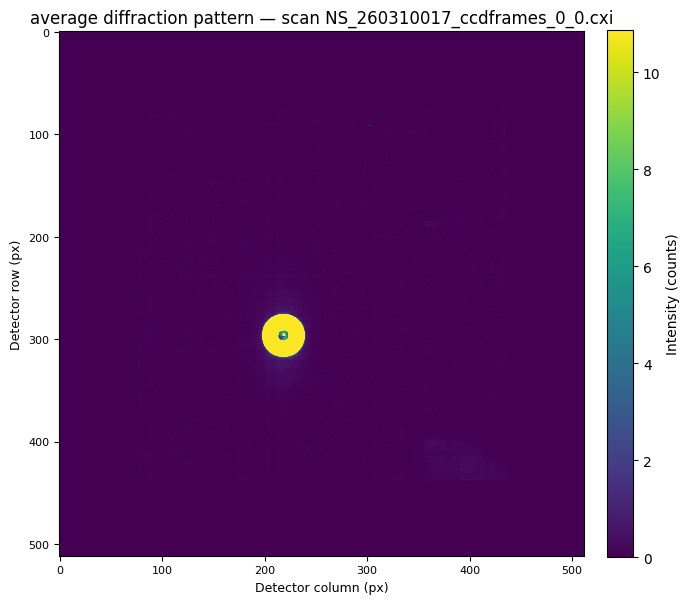

In [57]:
test_im = cxi_stack_pospol[0]
vmin, vmax = display_stretch(test_im, VMIN_PCTILE, VMAX_PCTILE)
    
fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(test_im, cmap=COLORMAP, vmin=vmin, vmax=vmax, origin='upper',
               interpolation='nearest')

# ── Decorations ───────────────────────────────────────────────────────────────
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Intensity (counts)', fontsize=10)

ax.set_title(f"average diffraction pattern — scan {CXI_FILE}", fontsize=12)
ax.set_xlabel("Detector column (px)", fontsize=9)
ax.set_ylabel("Detector row (px)", fontsize=9)
ax.tick_params(labelsize=8)

plt.tight_layout()
# plt.savefig(f"preview_frame_{PREVIEW_INDEX}.png", dpi=150, bbox_inches='tight')
plt.show()
# print(f"Preview saved → preview_frame_{PREVIEW_INDEX}.png")

## Plot energy for all scans too (I0?)

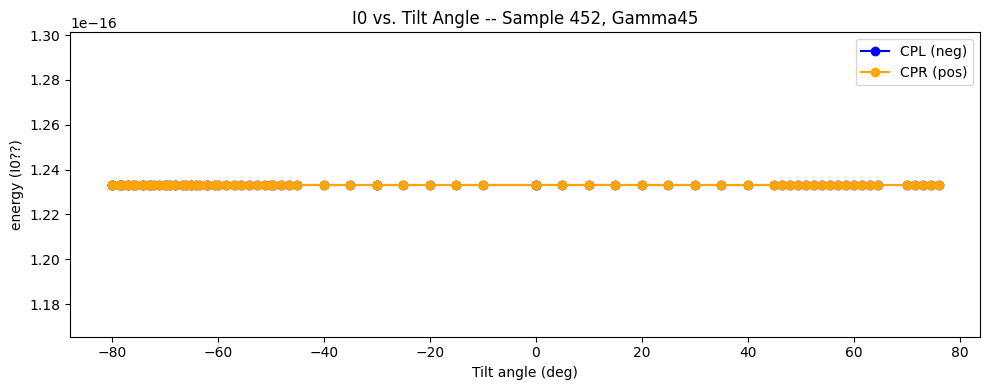

In [58]:
plt.figure(figsize=(10, 4))
plt.plot(angle_array_negpol, energy_negpol, marker='o', color='blue', label='CPL (neg)')
plt.plot(angle_array_pospol, energy_pospol, marker='o', color='orange', label='CPR (pos)')
plt.xlabel('Tilt angle (deg)')
plt.ylabel('energy (I0??)')
plt.title(f"I0 vs. Tilt Angle -- Sample {sample}, {Gamma}")
plt.legend()
plt.tight_layout()
plt.show()

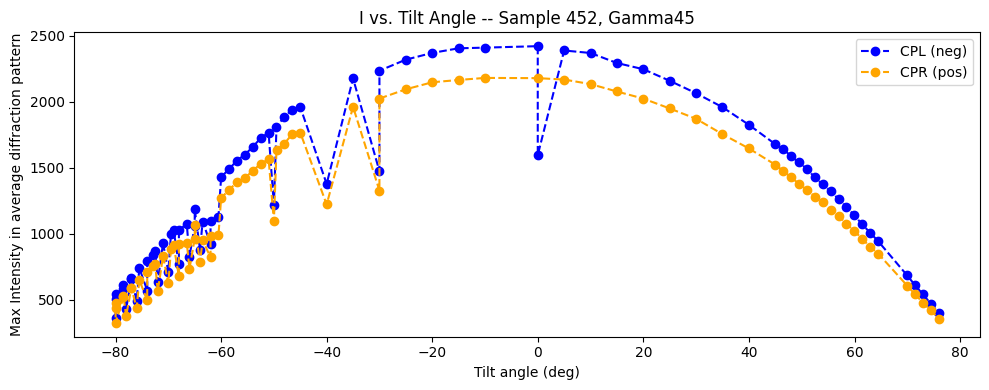

In [61]:
### max averaged diffraction intensity 
max_neg = []
max_pos = []

for k in range(cxi_stack_pospol.shape[0]):
    max_pos.append(np.max(cxi_stack_pospol[k]))


for k in range(cxi_stack_negpol.shape[0]):
    max_neg.append(np.max(cxi_stack_negpol[k]))
    
plt.figure(figsize=(10, 4))
plt.plot(angle_array_negpol, max_neg, marker='o', linestyle = '--', color='blue', label='CPL (neg)')
plt.plot(angle_array_pospol, max_pos, marker='o', linestyle = '--', color='orange', label='CPR (pos)')
plt.xlabel('Tilt angle (deg)')
plt.ylabel('Max Intensity in average diffraction pattern')
plt.title(f"I vs. Tilt Angle -- Sample {sample}, {Gamma}")
plt.legend()
plt.tight_layout()
plt.show()


In [62]:
save = True
modifier = 'all_scans_failed_psd'  
date = '_21MAR26_og_ptycho'
data_dir   = f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"

if save == True: 
    # np.savetxt(os.path.join(data_dir, f"unaligned_mean_{date}_{modifier}.txt"), mean_ua)
    # np.savetxt(os.path.join(data_dir, f"unaligned_var_{date}_{modifier}.txt"), variance_ua)
  
    np.savetxt(os.path.join(data_dir, f"energy_neg_{date}_{modifier}.txt"), energy_negpol)
    np.savetxt(os.path.join(data_dir, f"energy_pos_{date}_{modifier}.txt"), energy_pospol)

    np.savetxt(os.path.join(data_dir, f"max_avg_diff_neg_{date}_{modifier}.txt"), max_neg)
    np.savetxt(os.path.join(data_dir, f"max_avg_diff_pos_{date}_{modifier}.txt"), max_pos)

In [63]:
print(sample)
print(Gamma)
print(date) 

452
Gamma45
_21MAR26_og_ptycho


In [64]:
if not os.path.exists(data_dir):
        os.makedirs(data_dir)


# Saving Optical Density Image Stack
# amp_pospol = np.absolute(image_stack_pospol)
# amp_negpol = np.absolute(image_stack_negpol)
tifffile.imwrite(os.path.join(data_dir, f"avg_diff_pos_{Gamma}_{date}.tiff"), cxi_stack_pospol)
tifffile.imwrite(os.path.join(data_dir, f"avg_diff_neg_{Gamma}_{date}.tiff"), cxi_stack_negpol)

# #Saving Phase Image Stack
# phase_pospol = unwrap_phase(np.angle(image_stack_pospol))
# phase_negpol = unwrap_phase(np.angle(image_stack_negpol))
# tifffile.imwrite(os.path.join(save_dir, f"phase_pospol_stack_{date}_{ptycho_params}.tiff"), phase_pospol)
# tifffile.imwrite(os.path.join(save_dir, f"phase_negpol_stack_{date}_{ptycho_params}.tiff"), phase_negpol)

# Saving Angle Arrays as txt files
angles_pospol_corrected = angle_array_pospol * factor
angles_negpol_corrected = angle_array_negpol * factor

np.savetxt(os.path.join(data_dir, f"angles_diff_pospol_{Gamma}_{date}.txt"), angles_pospol_corrected)
np.savetxt(os.path.join(data_dir, f"angles_diff_negpol_{Gamma}_{date}.txt"), angles_negpol_corrected)



In [ ]:
stop

# Load in saved tiff files to compare diffraction patterns at different angles

In [92]:
# --- Sample Identity ---------------------------------------------------------
sample = "452"          # Sample identifier -- appears in all plot titles
Gamma  = "Gamma45"       # Polarization geometry (e.g. Gamma0, Gamma45, Gamma90)

data_dir   = f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"
# --- Data Date / Version Tag -------------------------------------------------
# Appended to input and output filenames to version-control processing runs.

# --- Plot Colors -------------------------------------------------------------
# color_1 / color_2: light/dark pair for NRMSE cosine fit plots.
if sample == '452':
    if Gamma == "Gamma90":
        date  = '_16MAR26_og_ptycho'
    if Gamma == "Gamma45":
        date  = '_21MAR26_og_ptycho'

# --- Build file paths --------------------------------------------------------
data_dir   = f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"

pos_images = f"avg_diff_pos_{Gamma}_{date}.tiff"
neg_images = f"avg_diff_neg_{Gamma}_{date}.tiff"
pos_angles = f"angles_diff_pospol_{Gamma}_{date}.txt"
neg_angles = f"angles_diff_pospol_{Gamma}_{date}.txt"

# --- Load stacks and angle arrays --------------------------------------------
image_stack_pospol = tifffile.imread(os.path.join(data_dir, pos_images))
image_stack_negpol = tifffile.imread(os.path.join(data_dir, neg_images))

angles_pospol = np.loadtxt(os.path.join(data_dir, pos_angles))
angles_negpol = np.loadtxt(os.path.join(data_dir, neg_angles))

print(f"Loaded: {data_dir}")
print(f"  Positive stack : {image_stack_pospol.shape}")
print(f"  Negative stack : {image_stack_negpol.shape}")
print(f"  Positive angles: {angles_pospol.shape}")
print(f"  Negative angles: {angles_negpol.shape}")


Loaded: /homes/emma/notebooks/RawData/452/Gamma45/
  Positive stack : (78, 512, 512)
  Negative stack : (79, 512, 512)
  Positive angles: (78,)
  Negative angles: (78,)


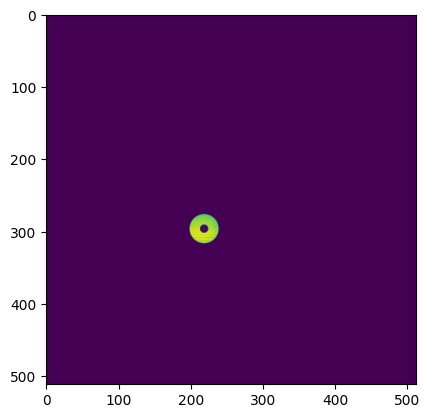

In [78]:
plt.imshow(image_stack_negpol[15])

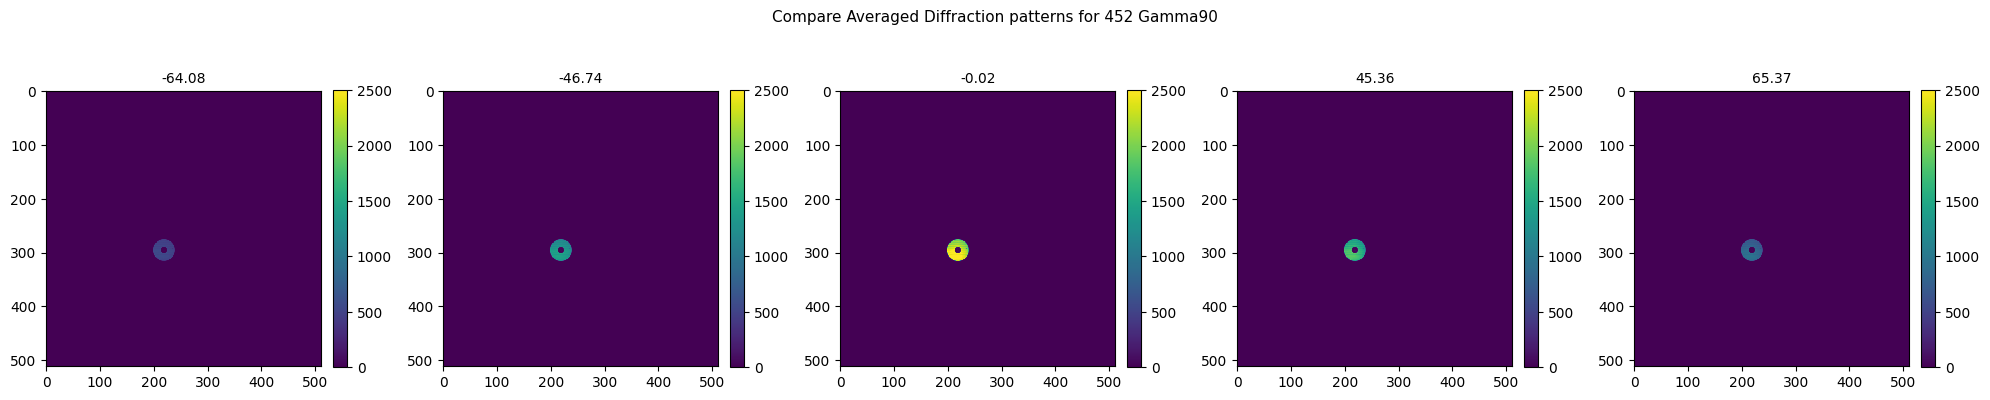

In [87]:
angles_compare = [2, 15, 30, 45, 60]
n = len(angles_compare)
ncols = min(n, 5)
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows))
axes = np.atleast_2d(axes)

for plot_idx, frame_idx in enumerate(angles_compare):
    ax = axes.flat[plot_idx]         # grab the correct subplot
    #vmin_i, vmax_i = display_stretch(image_stack_negpol[frame_idx], VMIN_PCTILE, VMAX_PCTILE)
    im = ax.imshow(image_stack_negpol[frame_idx], cmap=COLORMAP, vmin = 0, vmax = 2500,
              origin='upper', interpolation='nearest')
    ax.set_title(f"{angles_negpol[frame_idx]:.2f}", color='k', fontsize=10)
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    #cbar.set_label('Intensity (counts)', fontsize=10)
    
# Hide any unused subplot panels
for j in range(n, nrows * ncols):
    axes.flat[j].axis('off')

plt.suptitle(f"Compare Averaged Diffraction patterns for {sample} {Gamma}",
             color='k', fontsize=11, y=1.01)
plt.tight_layout()
plt.show()


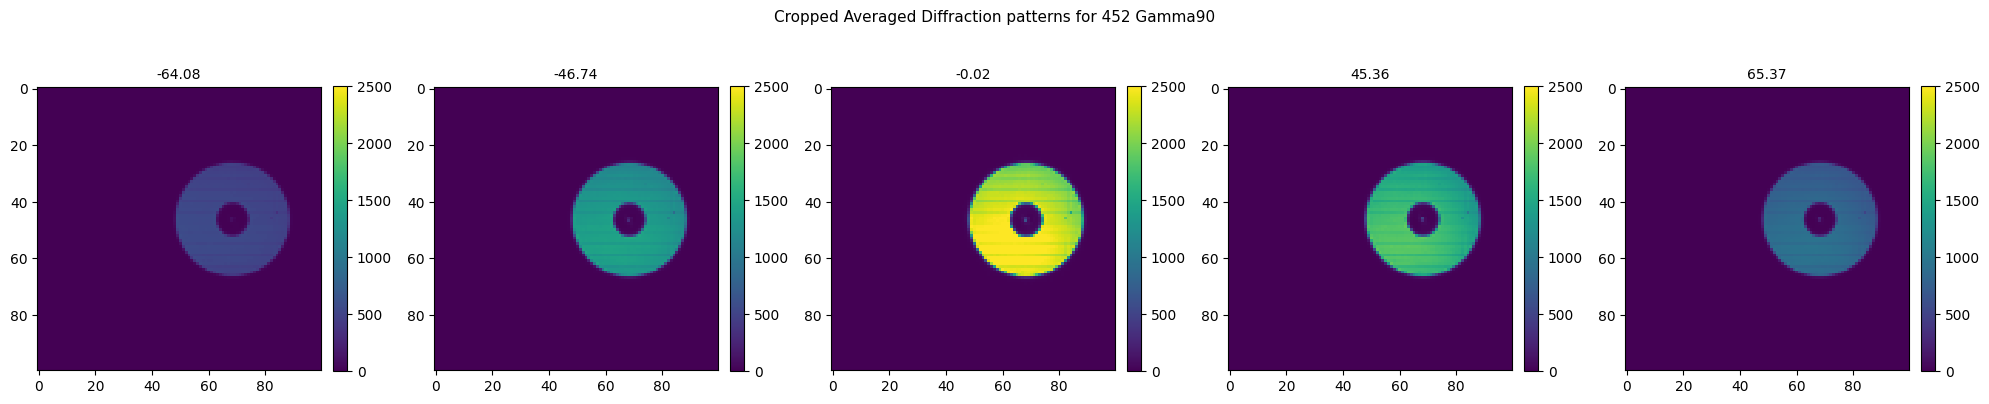

In [88]:
angles_compare = [2, 15, 30, 45, 60]
n = len(angles_compare)
ncols = min(n, 5)
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows))
axes = np.atleast_2d(axes)

for plot_idx, frame_idx in enumerate(angles_compare):
    ax = axes.flat[plot_idx]         # grab the correct subplot
    fr = image_stack_negpol[frame_idx]
    crop = fr[250:350, 150:250]
    #vmin_i, vmax_i = display_stretch(image_stack_negpol[frame_idx], VMIN_PCTILE, VMAX_PCTILE)
    im = ax.imshow(crop, cmap=COLORMAP, vmin = 0, vmax = 2500,
              origin='upper', interpolation='nearest')
    ax.set_title(f"{angles_negpol[frame_idx]:.2f}", color='k', fontsize=10)
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    #cbar.set_label('Intensity (counts)', fontsize=10)
    
# Hide any unused subplot panels
for j in range(n, nrows * ncols):
    axes.flat[j].axis('off')

plt.suptitle(f"Cropped Averaged Diffraction patterns for {sample} {Gamma}",
             color='k', fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

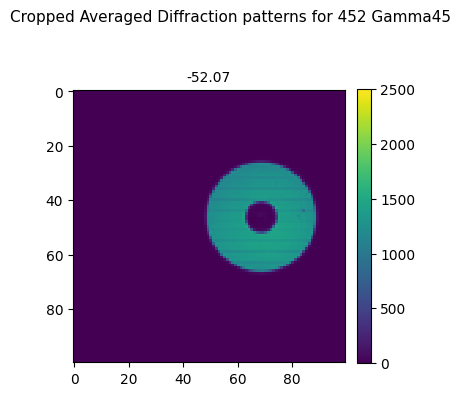

In [96]:
angles_compare = [31]
n = len(angles_compare)
ncols = min(n, 5)
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows))
axes = np.atleast_2d(axes)

for plot_idx, frame_idx in enumerate(angles_compare):
    ax = axes.flat[plot_idx]         # grab the correct subplot
    fr = image_stack_negpol[frame_idx]
    crop = fr[250:350, 150:250]
    #vmin_i, vmax_i = display_stretch(image_stack_negpol[frame_idx], VMIN_PCTILE, VMAX_PCTILE)
    im = ax.imshow(crop, cmap=COLORMAP, vmin = 0, vmax = 2500,
              origin='upper', interpolation='nearest')
    ax.set_title(f"{angles_negpol[frame_idx]:.2f}", color='k', fontsize=10)
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    #cbar.set_label('Intensity (counts)', fontsize=10)
    
# Hide any unused subplot panels
for j in range(n, nrows * ncols):
    axes.flat[j].axis('off')

plt.suptitle(f"Cropped Averaged Diffraction patterns for {sample} {Gamma}",
             color='k', fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
stop

In [ ]:
# Re-use `frames` from the contact-sheet cell, or reload if you skipped it:
# frames = load_frame_range(CXI_FILE, DATASET_PATH, SCAN_START, SCAN_STOP)

# ── 6a. Raw float32 multi-page TIFF ──────────────────────────────────────────
raw_tiff_path = OUTPUT_TIFF
tifffile.imwrite(
    raw_tiff_path,
    frames,                        # shape: (N, H, W), dtype float32
    photometric='minisblack',
    metadata={
        'axes':          'TYX',
        'pixel_size_m':  PIXEL_SIZE_M,
        'cxi_file':      str(CXI_FILE),
        'dataset_path':  DATASET_PATH,
        'scan_start':    SCAN_START,
        'scan_stop':     SCAN_STOP,
    }
)
size_mb = os.path.getsize(raw_tiff_path) / 1e6
print(f"Raw TIFF saved → {raw_tiff_path}  ({size_mb:.1f} MB, {len(frames)} pages)")


# ── 6b. Display-stretched 8-bit TIFF (optional, easier to open in ImageJ/FIJI) ─
def stretch_to_uint8(frame, vmin_pctile=1, vmax_pctile=99.5):
    vmin, vmax = display_stretch(frame, vmin_pctile, vmax_pctile)
    clipped = np.clip(frame, vmin, vmax)
    scaled  = (clipped - vmin) / (vmax - vmin + 1e-9) * 255
    return scaled.astype(np.uint8)

frames_8bit = np.stack([stretch_to_uint8(f, VMIN_PCTILE, VMAX_PCTILE) for f in frames])

display_tiff_path = OUTPUT_TIFF.replace('.tiff', '_display8bit.tiff')
tifffile.imwrite(
    display_tiff_path,
    frames_8bit,
    photometric='minisblack',
    metadata={'axes': 'TYX', 'pixel_size_m': PIXEL_SIZE_M}
)
size_mb2 = os.path.getsize(display_tiff_path) / 1e6
print(f"8-bit TIFF saved → {display_tiff_path}  ({size_mb2:.1f} MB)")

## 7. (Optional) Per-Frame Statistics
Useful for flagging blank / saturated / hit frames before downstream processing.

In [ ]:
import pandas as pd

stats = []
for i, fr in enumerate(frames):
    stats.append({
        'scan_index': SCAN_START + i,
        'mean':       float(fr.mean()),
        'std':        float(fr.std()),
        'min':        float(fr.min()),
        'max':        float(fr.max()),
        'p01':        float(np.percentile(fr, 1)),
        'p99':        float(np.percentile(fr, 99)),
        'saturated_px': int((fr == fr.max()).sum()),
    })

df = pd.DataFrame(stats)
display(df)

# Plot mean intensity per frame — a quick hit-rate proxy
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(df['scan_index'], df['mean'], marker='o', ms=4, lw=1.2)
ax.set_xlabel("Scan index")
ax.set_ylabel("Mean intensity")
ax.set_title("Mean intensity per frame")
plt.tight_layout()
plt.savefig("frame_stats.png", dpi=120, bbox_inches='tight')
plt.show()

# Export stats table
csv_path = f"frame_stats_{SCAN_START}-{SCAN_STOP}.csv"
df.to_csv(csv_path, index=False)
print(f"Stats exported → {csv_path}")

## 8. (Optional) Multi-File Batch Export
Loop over several `.cxi` files and append all frames to a single TIFF.

In [ ]:
CXI_DIR      = "."                 # Directory containing .cxi files
BATCH_OUTPUT = "batch_export.tiff" # Output TIFF for all files

cxi_files = sorted(Path(CXI_DIR).glob("*.cxi"))
print(f"Found {len(cxi_files)} .cxi files in '{CXI_DIR}'")

all_frames = []
for cxi_path in cxi_files:
    print(f"  Loading {cxi_path.name} ...", end=" ")
    try:
        batch_frames = load_frame_range(str(cxi_path), DATASET_PATH, SCAN_START, SCAN_STOP)
        all_frames.append(batch_frames)
        print(f"{len(batch_frames)} frames")
    except Exception as exc:
        print(f"SKIPPED ({exc})")

if all_frames:
    stacked = np.concatenate(all_frames, axis=0)
    tifffile.imwrite(BATCH_OUTPUT, stacked, photometric='minisblack',
                     metadata={'axes': 'TYX', 'pixel_size_m': PIXEL_SIZE_M})
    print(f"\nBatch TIFF saved → {BATCH_OUTPUT}  ({len(stacked)} total frames)")
else:
    print("No frames loaded — check CXI_DIR and DATASET_PATH.")